# 14 · The fUSI simulator and its signal modes

The `fusi_realtime` workload decodes intended movement direction from **functional
ultrasound imaging (fUSI)** volumes. There is no scanner in this repository, so every
experiment runs on a synthetic source, `workloads/fusi_realtime/sim.py`. This notebook
documents what that source models, which parts are published-basis and which are choices,
and what its guarantees are (determinism, separation of evaluation-only state).

| Element | Model | Basis |
|---|---|---|
| Planning region | ellipsoid, 18 % of voxels, cosine-tuned voxels with smoothly varying preferred direction (8 targets) | stands in for the posterior parietal planning activity decoded in Norman et al. 2021 and Griggs et al. 2024 |
| Hemodynamic mode | neural drive convolved with a gamma HRF peaking 1.5 s after onset | blood-volume lag of 1-2 s (Norman et al. 2021) |
| Reporter mode | first-order kinetics, $\tau$ = 0.2 s | **assumption**: the sources read report no in-vivo time constant for an acoustic calcium reporter |
| Physiology | non-sinusoidal cardiac pulsatility (1.2 Hz), respiratory motion (0.25 Hz), slow drift | RETROICOR regressors (Glover, Li, Ress 2000) remove it in notebook 15 |
| IQ ensemble | rank-1 coherent tissue clutter + decorrelated blood + thermal noise | SVD clutter filter (Demene et al. 2015) |

All amplitudes (gain 0.2, cardiac 6 %, speckle looks 64, ...) are this simulator's choices, not
measurements. Numbers produced here say nothing about real-scanner decoding accuracy.

## Conceptual model

One frame is one volume at 10 Hz. Per voxel $v$ and frame $t$ the *true* power Doppler is

$$P_v(t) = V_v \,\big(1 + g\,\textstyle\sum_d w_{vd}\, r_d(t)\big)\,\big(1 + \text{physio}_v(t)\big)\,\big(1 + \text{drift}_v(t)\big),$$

with vascular map $V_v$, tuning $w_{vd}$ (nonzero only in the planning region), and a
per-direction response $r_d(t)$. The response is the only part that depends on intent:

* hemodynamic: $r_d = (h * u_d)(t)$, $u_d$ = engagement while the user plans direction $d$, $h$ a
  unit-area gamma kernel;
* reporter: $r_d(t) = a\,r_d(t-\Delta) + (1-a)\,u_d(t)$ with $a = e^{-\Delta/\tau}$.

Because the response is **low rank in direction** (8 numbers per frame), a decoder only has to
recover which of 8 weights is active; spatial structure in $w_{vd}$ is what makes this possible.

Each frame carries *recorded* quantities (IQ or Doppler, cardiac and respiratory phase, task
events such as the instructed cue) and a separate **truth** record (`latent_intent`,
`engagement`, `lapsed`, `neural_drive`) that exists for evaluation only.

In [1]:
import os, sys, tempfile, time, warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("ML_LOG_LEVEL", "WARNING")   # keep structlog output out of the notebook
os.environ.setdefault("RAY_DEDUP_LOGS", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3})

# Every artifact this notebook creates lives in a fresh temp dir -- never in the repo's
# data/, artifacts/ or mlflow.db.
WORK = Path(tempfile.mkdtemp(prefix="nb14_"))
T0 = time.perf_counter()
print("workspace:", WORK)

workspace: /var/folders/vx/0jy3t_qx56q4d0qpnmgs008r0000gn/T/nb14_vahxn7op


In [2]:
from ml_platform.workloads.fusi_realtime.config import SimConfig
from ml_platform.workloads.fusi_realtime import sim as S
from ml_platform.workloads.fusi_realtime.preprocess import clutter_filter

GRID = (16, 16, 16)                          # small on purpose: nothing here needs 32^3
base = SimConfig(grid=GRID, lapse_rate=0.0)  # no lapses for the clean response plots
FS = base.frame_rate_hz
print(f"grid {GRID}, {FS:g} Hz, ensemble {base.n_ensemble}, directions {base.n_directions}")
print("label delay (s):", {m: S.label_delay_s(base.model_copy(update={"signal_mode": m}))
                            for m in ("hemodynamic", "reporter")})

grid (16, 16, 16), 10 Hz, ensemble 8, directions 8
label delay (s): {'hemodynamic': 1.0, 'reporter': 0.3}


## 1 · Anatomy: planning region and tuning

`SubjectAnatomy` is built once per subject (seeded by `sim.seed` and the subject id) and is
shared by all sessions of that subject. Preferred direction varies smoothly in space, so
neighbouring voxels carry similar information.

planning voxels: 738 / 4096 = 18.0%


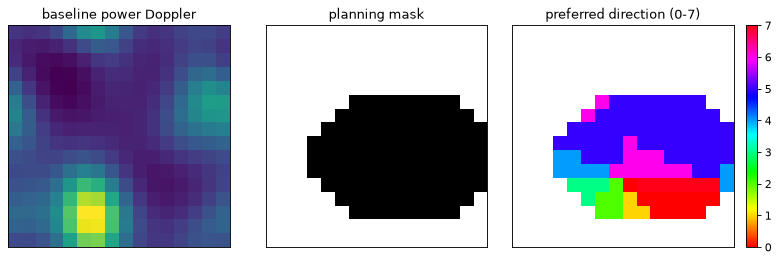

In [3]:
sim0 = S.FusiSimulator(base, subject=0, session=0, emit="doppler")
an = sim0.anatomy
pref = np.argmax(an.tuning, axis=1).reshape(GRID)
plan = an.planning.reshape(GRID)
print(f"planning voxels: {plan.sum()} / {plan.size} = {plan.mean():.1%}")
zc = int(np.argwhere(plan)[:, 2].mean())
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
im0 = ax[0].imshow(an.vascular.reshape(GRID)[:, :, zc].T, origin="lower"); ax[0].set_title("baseline power Doppler")
ax[1].imshow(plan[:, :, zc].T, origin="lower", cmap="gray_r"); ax[1].set_title("planning mask")
pp = np.where(plan, pref, np.nan)[:, :, zc].T
im2 = ax[2].imshow(pp, origin="lower", cmap="hsv", vmin=0, vmax=7); ax[2].set_title("preferred direction (0-7)")
for a in ax: a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.colorbar(im2, ax=ax[2], fraction=0.046); plt.tight_layout(); plt.show()

## 2 · Hemodynamic vs reporter response

Cue-triggered average of the normalised power Doppler $D/V - 1$ over the voxels tuned to that
trial's cue (tuning > 0.5), across ~14 trials, with the pre-cue mean subtracted (the previous trial's response and mean physiology otherwise leave an offset). Speckle (Gamma noise with 64 looks) and
physiology remain in the signal; averaging over voxels and trials exposes the response. Dotted
lines mark cue onset and the end of the 3 s planning phase.

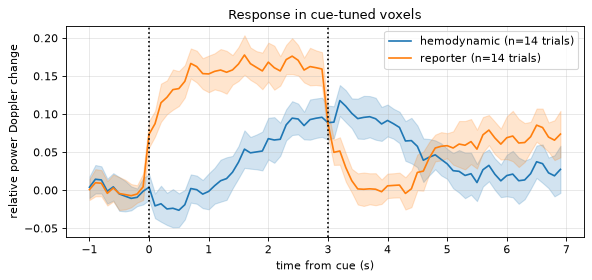

hemodynamic  peak 0.118 at +3.2 s after cue
reporter     peak 0.178 at +1.6 s after cue
time to reach half of the plateau (s), hemodynamic vs reporter: {'hemodynamic': 2.0, 'reporter': 0.2}


In [4]:
def cue_triggered(mode, n_frames=700, pre=10, post=70):
    cfg = base.model_copy(update={"signal_mode": mode})
    sim = S.FusiSimulator(cfg, subject=0, session=1, emit="doppler")
    frames = sim.run(n_frames)
    D = np.stack([f.doppler.reshape(-1) for f in frames]) / sim.anatomy.vascular[None, :] - 1.0
    ev, tr = S.frames_to_tables(frames)
    onsets = ev.index[(ev.phase == "plan") & (ev.phase.shift(1) == "rest")].to_numpy()
    segs = []
    for o in onsets:
        if o - pre < 0 or o + post > n_frames:
            continue
        voxels = sim.anatomy.tuning[:, ev.cue_direction[o]] > 0.5
        seg = D[o - pre:o + post][:, voxels].mean(axis=1)
        segs.append(seg - seg[:pre].mean())      # subtract the pre-cue baseline
    segs = np.array(segs)
    return (np.arange(-pre, post) / FS), segs

fig, ax = plt.subplots(figsize=(7.5, 3.6))
curves = {}
for mode, col in (("hemodynamic", "C0"), ("reporter", "C1")):
    t, segs = cue_triggered(mode)
    m, se = segs.mean(0), segs.std(0) / np.sqrt(len(segs))
    curves[mode] = m
    ax.plot(t, m, color=col, label=f"{mode} (n={len(segs)} trials)")
    ax.fill_between(t, m - se, m + se, color=col, alpha=0.2)
ax.axvline(0, ls=":", c="k"); ax.axvline(base.plan_s, ls=":", c="k")
ax.set(xlabel="time from cue (s)", ylabel="relative power Doppler change", title="Response in cue-tuned voxels")
ax.legend(); plt.tight_layout(); plt.show()
for mode, m in curves.items():
    t_pk = t[10 + np.argmax(m[10:60])]
    print(f"{mode:12s} peak {m[10:60].max():.3f} at {t_pk:+.1f} s after cue")
print("time to reach half of the plateau (s), hemodynamic vs reporter:",
      {k: round(float(t[10 + np.argmax(v[10:] > 0.5 * v[10:60].max())]), 2) for k, v in curves.items()})

The reporter response follows the neural drive within a few frames, the hemodynamic response
lags it by 1-2 s and smooths the boxcar. `label_delay_s` encodes the practical
consequence: a frame only gets a training label once the signal can be visible
(about 1.0 s after cue for hemodynamic, 0.3 s for the reporter assumption). Faster kinetics are
what would let a decoder run at a higher update rate than the 2 Hz of the published fUS-BMI
(Griggs et al. 2024), but nothing here measures that.

## 3 · Cardiac and respiratory physiology

With `signal_gain = 0` there is no task signal left, only physiology, drift and speckle. The
voxel-averaged log power shows the spectral lines at the cardiac and respiratory frequencies
(plus a cardiac harmonic, because the pulse is non-sinusoidal), and binning by recorded
phase recovers the waveform shapes. This is the structure RETROICOR regresses out.

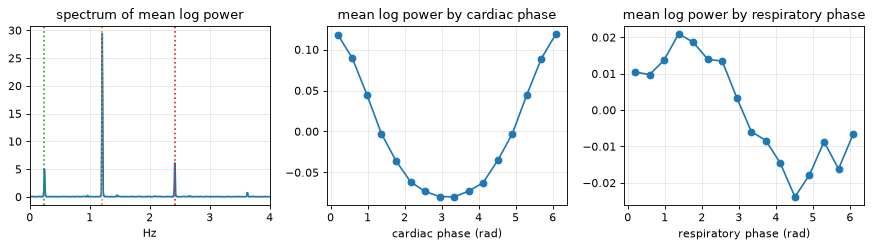

session cardiac f = 1.210 Hz, respiratory f = 0.245 Hz (configured 1.2 / 0.25 Hz, jittered per session)


In [5]:
cfg_p = base.model_copy(update={"signal_gain": 0.0, "drift_per_min": 0.0})
simp = S.FusiSimulator(cfg_p, subject=0, session=2, emit="doppler")
fr = simp.run(1200)
y = np.log(np.stack([f.doppler.mean() for f in fr]))
y = y - y.mean()
card = np.array([f.cardiac_phase for f in fr]); resp = np.array([f.respiratory_phase for f in fr])

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
freqs = np.fft.rfftfreq(len(y), 1 / FS); amp = np.abs(np.fft.rfft(y * np.hanning(len(y))))
ax[0].plot(freqs, amp); ax[0].set(xlabel="Hz", title="spectrum of mean log power", xlim=(0, 4))
for f, c in ((simp.f_card, "C1"), (2 * simp.f_card, "C3"), (simp.f_resp, "C2")):
    ax[0].axvline(f, color=c, ls=":")
for k, (ph, nm) in enumerate(((card, "cardiac"), (resp, "respiratory"))):
    bins = np.linspace(0, 2 * np.pi, 17); idx = np.digitize(ph, bins) - 1
    prof = np.array([y[idx == b].mean() for b in range(16)])
    ax[k + 1].plot(0.5 * (bins[1:] + bins[:-1]), prof, "o-")
    ax[k + 1].set(xlabel=f"{nm} phase (rad)", title=f"mean log power by {nm} phase")
plt.tight_layout(); plt.show()
print(f"session cardiac f = {simp.f_card:.3f} Hz, respiratory f = {simp.f_resp:.3f} Hz "
      "(configured 1.2 / 0.25 Hz, jittered per session)")

Frequencies are jittered ±5 % per session and the phases start at random offsets, so a
regression fitted on one session transfers to another only through the *recorded phase*, not
through a fixed frequency. That is why the phases are stored with the data and are an allowed
decoder input.

## 4 · IQ ensemble: tissue is rank 1

A frame in `emit="iq"` mode holds an ensemble of 8 compound frames per voxel. Stack them as a
Casorati matrix $M$ (ensemble × voxels). Tissue is the same complex reflectivity in all
ensemble members up to one global phase ramp (respiratory motion), so it is exactly rank 1 and
30 dB stronger than blood. Blood decorrelates across the ensemble and fills the remaining
singular values.

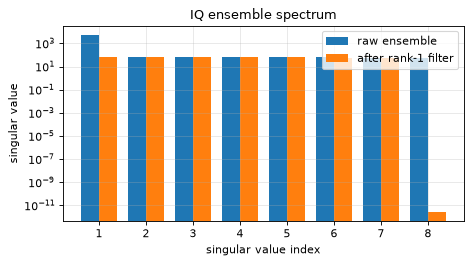

s1 / s2 before filter: 90.6x  (30 dB clutter ~ 32x in amplitude, reduced by the blood floor)
s1 after filter: 64.31 vs s2 before: 64.31  (tissue component removed; s_last after = 1.7e-12)
corr(power Doppler, vascular map): no filter 0.478, rank-1 filter 0.937
mean power: no filter 1036.1 vs filtered 0.92 (true mean ~1.00)


In [6]:
simq = S.FusiSimulator(base, subject=0, session=3, emit="iq")
frq = simq.run(5)[-1]
M = frq.iq.reshape(base.n_ensemble, -1).astype(np.complex128)
s_before = np.linalg.svd(M, compute_uv=False)
U, s, Vh = np.linalg.svd(M, full_matrices=False)
M_f = M - U[:, :1] @ (U[:, :1].conj().T @ M)                  # remove rank-1 tissue
s_after = np.linalg.svd(M_f, compute_uv=False)

fig, ax = plt.subplots(figsize=(6, 3.4))
w = 0.38; k = np.arange(1, len(s) + 1)
ax.bar(k - w / 2, s_before, w, label="raw ensemble"); ax.bar(k + w / 2, s_after + 1e-12, w, label="after rank-1 filter")
ax.set(yscale="log", xlabel="singular value index", ylabel="singular value", title="IQ ensemble spectrum"); ax.legend()
plt.tight_layout(); plt.show()
print(f"s1 / s2 before filter: {s_before[0] / s_before[1]:.1f}x  (30 dB clutter ~ {10 ** (30 / 20):.0f}x in amplitude, reduced by the blood floor)")
print(f"s1 after filter: {s_after[0]:.2f} vs s2 before: {s_before[1]:.2f}  (tissue component removed; s_last after = {s_after[-1]:.1e})")

# Power Doppler with and without the filter, versus the true vascular map
p0 = clutter_filter(frq.iq, 0).ravel(); p1 = clutter_filter(frq.iq, 1).ravel()
V = simq.anatomy.vascular
print(f"corr(power Doppler, vascular map): no filter {np.corrcoef(p0, V)[0, 1]:.3f}, "
      f"rank-1 filter {np.corrcoef(p1, V)[0, 1]:.3f}")
print(f"mean power: no filter {p0.mean():.1f} vs filtered {p1.mean():.2f} (true mean ~{V.mean():.2f})")

Without the filter the 'power Doppler' is tissue power (random reflectivity), uncorrelated with
perfusion; after removing the first singular component the voxel map follows the vascular
baseline again. Real ensembles hold 100-300 frames and tissue is not exactly rank 1 (it
moves non-rigidly); `clutter_rank` in `PreprocessConfig` is the knob, and Demene et al. 2015
select the cut-off adaptively.

## 5 · Determinism

All randomness comes from generators seeded by `(sim.seed, subject, session)`. The same
arguments give bit-identical frames, which is what makes the Zarr session store write-once
(same key, same content) and lets tests compare streaming against batch exactly.

In [7]:
def digest(sim, n=20):
    fr = sim.run(n)
    return fr, [f.iq for f in fr]

a_fr, a = digest(S.FusiSimulator(base, subject=0, session=7, emit="iq"))
b_fr, b = digest(S.FusiSimulator(base, subject=0, session=7, emit="iq"))
c_fr, c = digest(S.FusiSimulator(base, subject=0, session=8, emit="iq"))
d_fr, d = digest(S.FusiSimulator(base.model_copy(update={"seed": 1}), subject=0, session=7, emit="iq"))
same = all(np.array_equal(x, y) for x, y in zip(a, b))
assert same
print("same (seed, subject, session):  iq identical =", same,
      "| truth identical =", all(x.truth == y.truth for x, y in zip(a_fr, b_fr)))
print("different session:               iq identical =", all(np.array_equal(x, y) for x, y in zip(a, c)))
print("different seed:                  iq identical =", all(np.array_equal(x, y) for x, y in zip(a, d)))
print("anatomy shared across sessions of a subject:",
      np.array_equal(S.FusiSimulator(base, subject=0, session=7).anatomy.tuning,
                     S.FusiSimulator(base, subject=0, session=8).anatomy.tuning))

same (seed, subject, session):  iq identical = True | truth identical = True
different session:               iq identical = False
different seed:                  iq identical = False
anatomy shared across sessions of a subject: True


## 6 · Closed loop: feedback changes the signal

With `closed_loop=True`, `feedback(velocity)` integrates the decoded cursor velocity towards the
instructed target; reaching progress 1 ends the trial early as a success. The simulated user
raises its **engagement** (response amplitude) after successes and lowers it after timeouts
(`feedback_learning_rate` 0.15 per trial, bounds 0.5-1.5). A decoder's quality therefore
changes the data it is later evaluated on.

Three stand-in decoders: an *oracle* that outputs the instructed direction, *random* velocity
with no information, and *anti* (the opposite direction). The oracle uses the task event
`cue_direction` only to emulate a perfect decoder; it never touches truth columns.

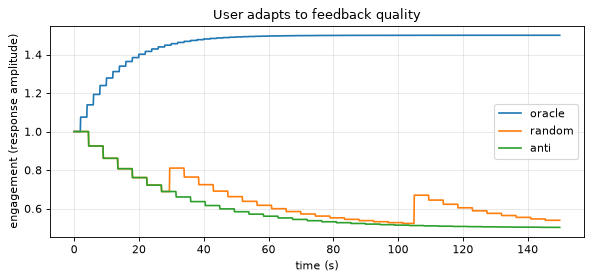

,trials,successes,success rate,final engagement,mean engagement
decoder,,,,,
oracle,75,75,1.0000,1.5000,1.4556
random,34,2,0.0588,0.5393,0.6507
anti,33,0,0.0000,0.5023,0.5996


In [8]:
def run_closed_loop(policy, n_frames=1500, seed=0):
    cfg = base.model_copy(update={"seed": 0})
    sim = S.FusiSimulator(cfg, subject=0, session=20, emit="doppler", closed_loop=True)
    rng = np.random.default_rng(seed)
    eng = []
    for _ in range(n_frames):
        f = sim.next_frame()
        eng.append(f.truth.engagement)
        if f.cue_direction >= 0:
            u = sim.dir_vecs[f.cue_direction]
            v = {"oracle": 2.0 * u, "anti": -2.0 * u, "random": 2.0 * sim.dir_vecs[rng.integers(8)]}[policy]
        else:
            v = np.zeros(2)
        sim.feedback(v)
    return np.array(eng), sim

fig, ax = plt.subplots(figsize=(7.5, 3.6)); rows = []
for pol in ("oracle", "random", "anti"):
    eng, sim = run_closed_loop(pol)
    ax.plot(np.arange(len(eng)) / FS, eng, label=pol)
    ok = int(sum(sim.outcomes))
    rows.append({"decoder": pol, "trials": len(sim.outcomes), "successes": ok,
                 "success rate": ok / max(len(sim.outcomes), 1), "final engagement": eng[-1],
                 "mean engagement": eng.mean()})
ax.set(xlabel="time (s)", ylabel="engagement (response amplitude)", title="User adapts to feedback quality"); ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("decoder")

A good decoder shortens trials (more trials per minute) and raises engagement towards 1.5, so
the signal gets *stronger*; a bad one lowers engagement towards 0.5 and weakens it. Two
consequences for evaluation: closed-loop accuracy is not comparable with open-loop accuracy
on a fixed recording, and a decoder trained on data recorded under one feedback regime is
evaluated on data whose signal-to-noise ratio it influenced.

## 7 · Events versus truth

`frames_to_tables` returns two tables. **Events** hold what a scanner and task controller
would record: task phase, instructed cue, physiological phases. **Truth** holds hidden
simulator state. Labels for training (`frame_labels`) come from events only, so they inherit
the realistic imperfection that the user may lapse: the instructed cue is then not the
user's intent.

In [9]:
cfg_l = base.model_copy(update={"lapse_rate": 0.25})                 # exaggerated for the demo
siml = S.FusiSimulator(cfg_l, subject=0, session=30, emit="doppler")
frs = siml.run(900)
events, truth = S.frames_to_tables(frs)
print("events columns:", list(events.columns))
print("truth columns: ", list(truth.columns))
print("latent columns that must never be decoder inputs:", S.LATENT_COLUMNS)
print("overlap of column names other than the 'frame' key:",
      (set(events.columns) & set(truth.columns)) - {"frame"})
labels = S.frame_labels(events, cfg_l)
lab = labels >= 0
lapsed_lab = (truth.latent_intent.to_numpy() == -1) & lab
print(f"labelled frames: {lab.sum()} / {len(labels)}; of those, {lapsed_lab.sum()} "
      f"({lapsed_lab.sum() / lab.sum():.0%}) come from lapsed trials where the label is the cue but latent_intent = -1")
events.iloc[40:46]

events columns: ['frame', 't_s', 'trial', 'phase', 'cue_direction', 'cardiac_phase', 'respiratory_phase']
truth columns:  ['frame', 'latent_intent', 'engagement', 'lapsed', 'neural_drive']
latent columns that must never be decoder inputs: ('latent_intent', 'engagement', 'lapsed', 'neural_drive')
overlap of column names other than the 'frame' key: set()
labelled frames: 400 / 900; of those, 120 (30%) come from lapsed trials where the label is the cue but latent_intent = -1


,frame,t_s,trial,phase,cue_direction,cardiac_phase,respiratory_phase
40,40,4.0,0,plan,3,1.2174,0.1976
41,41,4.1,0,plan,3,1.9549,0.3510
42,42,4.2,0,plan,3,2.6925,0.5044
43,43,4.3,0,plan,3,3.4300,0.6578
44,44,4.4,0,plan,3,4.1676,0.8112
45,45,4.5,-1,rest,-1,4.9051,0.9646


In [10]:
truth.iloc[40:46]

,frame,latent_intent,engagement,lapsed,neural_drive
40,40,3,1.0,False,1.0
41,41,3,1.0,False,1.0
42,42,3,1.0,False,1.0
43,43,3,1.0,False,1.0
44,44,3,1.0,False,1.0
45,45,-1,1.0,False,0.0


Lapsed trials are label noise by construction: a decoder cannot be accurate on frames where the
user did not plan the cued direction. Using `truth.latent_intent` as a label would hide that
and, worse, would make evaluation depend on information no real recording has. The
feature-schema check in notebook 15 refuses any decoder input named like a truth column.

## Pitfalls

* **Simulator numbers are not scanner numbers.** Accuracy, latency of the response and
  noise levels are properties of the chosen parameters. Treat results as tests of the
  *pipeline* (leakage control, streaming equivalence, latency), not of decoding performance.
* **Reporter time constant is an assumption** (0.2 s). Conclusions about update rates under
  reporter kinetics depend on it.
* **Speckle is i.i.d. Gamma** across voxels and frames; real speckle is spatially correlated.
* **Rank-1 tissue is optimistic**; with real tissue motion the filter rank and ensemble
  length matter much more.
* **Closed-loop data depend on the decoder** that was in the loop (engagement adapts).

## Exercise

1. Set `reporter_tau_s` to 0.1 and 0.5 s and measure, with the cue-triggered average, the time
   to half-plateau. How does `label_delay_s` change?
2. Increase `clutter_db` to 50 and repeat the singular-value plot. At what clutter level does
   `clutter_rank=1` stop recovering the vascular map (correlation with `anatomy.vascular`)?
3. Make `respiratory_amp` 0.2. Does the respiratory spectral line grow linearly? What would the
   loss of un-regressed respiration do to a decoder that averages 6 frames?

In [11]:
import shutil
shutil.rmtree(WORK, ignore_errors=True)
print(f"done in {time.perf_counter() - T0:.1f}s; workspace removed")

done in 2.0s; workspace removed
